# Intenção de Compra em E-commerce
**Projeto de Pesquisa Acadêmica**  
**Autor:** Igor Ryan de Campos Ianes  
**Instituição:** Universidade Federal de São Carlos
**Data:** Novembro de 2026

## 1. Resumo e Fonte dos Dados

Este notebook apresenta o protocolo de extração, auditoria de integridade e análise estatística dos dados utilizados no artigo *Diferenças no comportamento de navegação entre sessões convertidas e não convertidas: uma análise estatística no comércio eletrônico*.

- **Base de dados:** Online Shoppers Purchasing Intention Dataset.
- **Repositório:** UCI Machine Learning Repository (ID: 468).
- **Referência da base:** Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). *Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks*. Neural Computing and Applications, 31(10), 6893–6908.
- **Escopo:** O conjunto de dados contém 12.330 registros de sessões de navegação, com 17 atributos preditivos e uma variável-alvo binária (`Revenue`), que indica se a sessão resultou em compra.
- **Objetivo da análise:** Comparar as distribuições de `ProductRelated_Duration` e `PageValues` entre sessões com e sem compra, utilizando métodos estatísticos e medidas de tamanho de efeito.
- **Limitação:** Os registros representam sessões de navegação, não necessariamente indivíduos distintos. Portanto, não é possível garantir a independência entre sessões pertencentes a um mesmo visitante.

## 2. Configuração do Ambiente e Reprodutibilidade
Nesta seção, instalamos as dependências necessárias, importamos as bibliotecas analíticas e configuramos os parâmetros globais de visualização para garantir que os resultados sejam idênticos em qualquer ambiente de execução.

In [1]:
# Instalação do pacote oficial do repositório UCI
!pip install -q ucimlrepo

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from ucimlrepo import fetch_ucirepo
from scipy import stats
from scipy.stats import spearmanr, mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Ambiente configurado com sucesso.")

Ambiente configurado com sucesso.


## 3. Extração Oficial e Dicionário de Variáveis
Os dados são carregados diretamente via API oficial (`ucimlrepo`), garantindo que não houve manipulação prévia nos arquivos brutos.

In [2]:
# Extração do dataset
dataset = fetch_ucirepo(id=468)

X = dataset.data.features
y = dataset.data.targets
df = pd.concat([X, y], axis=1)

# Exibição organizada dos metadados oficiais
print(f"Dataset: {dataset.metadata['name']}")
print(f"DOI Oficial: {dataset.metadata['dataset_doi']}")
print(f"Última atualização no repositório: {dataset.metadata['last_updated']}\n")

# Tabela estruturada das variáveis
variaveis_info = dataset.variables[['name', 'role', 'type', 'missing_values']]
display(variaveis_info.style.set_caption("Tabela 1: Estrutura Oficial das Variáveis do Conjunto de Dados"))

Dataset: Online Shoppers Purchasing Intention Dataset
DOI Oficial: 10.24432/C5F88Q
Última atualização no repositório: Thu Jan 11 2024



,name,role,type,missing_values
0,Administrative,Feature,Integer,no
1,Administrative_Duration,Feature,Integer,no
2,Informational,Feature,Integer,no
3,Informational_Duration,Feature,Integer,no
4,ProductRelated,Feature,Integer,no
5,ProductRelated_Duration,Feature,Continuous,no
6,BounceRates,Feature,Continuous,no
7,ExitRates,Feature,Continuous,no
8,PageValues,Feature,Integer,no
9,SpecialDay,Feature,Integer,no


## 4. Auditoria de Integridade e Verificabilidade
Para assegurar a rastreabilidade dos números reportados na seção de *Metodologia* do artigo, executa-se abaixo a verificação formal de dimensionalidade, valores ausentes, consistência de tipos e registros duplicados.

In [3]:
def auditar_dataset(dataframe, target_col='Revenue'):
    total_linhas, total_colunas = dataframe.shape
    nulos_total = dataframe.isnull().sum().sum()
    duplicadas = dataframe.duplicated().sum()
    constantes = [col for col in dataframe.columns if dataframe[col].nunique() <= 1]

    resumo_geral = pd.DataFrame({
        'Métrica de Auditoria': [
            'Total de Instâncias (Sessões)',
            'Total de Atributos (Features + Target)',
            'Total de Valores Ausentes (NaN)',
            'Linhas Exatamente Duplicadas',
            'Percentual de Duplicatas (%)',
            'Atributos Constantes (Variância Zero)'
        ],
        'Valor Verificado': [
            f"{total_linhas:,}".replace(",", "."),
            total_colunas,
            nulos_total,
            duplicadas,
            f"{(duplicadas / total_linhas * 100):.2f}%",
            len(constantes)
        ]
    })
    display(resumo_geral.style.hide(axis='index').set_caption("Tabela 2: Sumário de Integridade da Base de Dados"))

    # Tabela de Distribuição da Variável-Alvo
    contagem = dataframe[target_col].value_counts()
    percentual = dataframe[target_col].value_counts(normalize=True) * 100
    resumo_alvo = pd.DataFrame({
        'Classe (Revenue)': contagem.index.map({False: 'Negativa (False - Sem Compra)', True: 'Positiva (True - Com Compra)'}),
        'Frequência Absoluta (n)': contagem.values,
        'Proporção Relativa (%)': percentual.round(2).values
    })
    display(resumo_alvo.style.hide(axis='index').set_caption("Tabela 3: Distribuição da Variável-Alvo (Desbalanceamento de Classes)"))

auditar_dataset(df)

Métrica de Auditoria,Valor Verificado
Total de Instâncias (Sessões),12.330
Total de Atributos (Features + Target),18
Total de Valores Ausentes (NaN),0
Linhas Exatamente Duplicadas,125
Percentual de Duplicatas (%),1.01%
Atributos Constantes (Variância Zero),0


Classe (Revenue),Frequência Absoluta (n),Proporção Relativa (%)
Negativa (False - Sem Compra),10422,84.530000
Positiva (True - Com Compra),1908,15.470000


## 5. Análise Estatística Descritiva
A tabela a seguir consolida as medidas de tendência central, dispersão e separatrizes (quartis) dos atributos numéricos contínuos e discretos.

In [4]:
variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

grupos = {
    False: 'Sem compra',
    True: 'Com compra'
}

resultados_descritivos = []

for variavel in variaveis_artigo:
    for revenue, nome_grupo in grupos.items():
        dados = df.loc[df['Revenue'] == revenue, variavel]

        resultados_descritivos.append({
            'Variável': variavel,
            'Resultado': nome_grupo,
            'N': dados.count(),
            'Média': dados.mean(),
            'Desvio padrão': dados.std(),
            'Mediana': dados.median(),
            'Q1': dados.quantile(0.25),
            'Q3': dados.quantile(0.75)
        })

tabela_descritiva_artigo = pd.DataFrame(resultados_descritivos)

display(
    tabela_descritiva_artigo.style
    .format({
        'Média': '{:,.2f}',
        'Desvio padrão': '{:,.2f}',
        'Mediana': '{:,.2f}',
        'Q1': '{:,.2f}',
        'Q3': '{:,.2f}'
    })
    .set_caption("Estatísticas descritivas das métricas por resultado da sessão")
)


,Variável,Resultado,N,Média,Desvio padrão,Mediana,Q1,Q3
0,ProductRelated_Duration,Sem compra,10422,"1,069.99","1,803.80",510.19,151.00,"1,331.82"
1,ProductRelated_Duration,Com compra,1908,"1,876.21","2,312.21","1,109.91",541.91,"2,266.01"
2,PageValues,Sem compra,10422,1.98,9.07,0.00,0.00,0.00
3,PageValues,Com compra,1908,27.26,35.19,16.76,3.64,38.90


## 6. Análise da Proporção de Valores Zero

Nesta etapa, investiga-se a frequência de valores iguais a zero nas variáveis `ProductRelated_Duration` e `PageValues`, separadamente para sessões com e sem compra. Essa análise permite identificar características das distribuições que podem influenciar a interpretação das comparações estatísticas.

A proporção de zeros é calculada em relação ao total de observações de cada grupo, permitindo verificar se a ocorrência de valores nulos numéricos (zeros) apresenta diferenças entre os resultados das sessões. Essa verificação é particularmente relevante para `PageValues`, uma vez que valores zero podem representar sessões nas quais não houve geração de valor associado às páginas visitadas.

Os resultados são apresentados em valores absolutos e percentuais, de modo a caracterizar as distribuições antes da realização dos testes inferenciais.


In [5]:
variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

resultados_zeros = []

for variavel in variaveis_artigo:
    for revenue, nome_grupo in [(False, 'Sem compra'), (True, 'Com compra')]:
        dados = df.loc[df['Revenue'] == revenue, variavel]

        quantidade_zeros = (dados == 0).sum()
        total = dados.count()

        resultados_zeros.append({
            'Variável': variavel,
            'Resultado': nome_grupo,
            'Total': total,
            'Zeros': quantidade_zeros,
            'Percentual de zeros (%)': (quantidade_zeros / total) * 100
        })

tabela_zeros = pd.DataFrame(resultados_zeros)

display(
    tabela_zeros.style
    .format({'Percentual de zeros (%)': '{:.2f}%'})
    .set_caption("Proporção de valores zero por variável e resultado da sessão")
)

,Variável,Resultado,Total,Zeros,Percentual de zeros (%)
0,ProductRelated_Duration,Sem compra,10422,742,7.12%
1,ProductRelated_Duration,Com compra,1908,13,0.68%
2,PageValues,Sem compra,10422,9230,88.56%
3,PageValues,Com compra,1908,370,19.39%


## 7. Visualização das Distribuições

Nesta etapa, são construídos histogramas para as variáveis `ProductRelated_Duration` e `PageValues`, considerando separadamente as sessões com e sem compra. O objetivo é observar o formato das distribuições, sua dispersão e a concentração das observações, complementando as estatísticas descritivas apresentadas anteriormente.

A visualização das distribuições auxilia na identificação de assimetria, concentração de valores e possíveis diferenças entre os grupos. Essas características também contribuem para justificar a utilização de métodos estatísticos não paramétricos na comparação entre as sessões.

Os histogramas são apresentados na escala original das variáveis, permitindo preservar a interpretação direta dos valores observados.


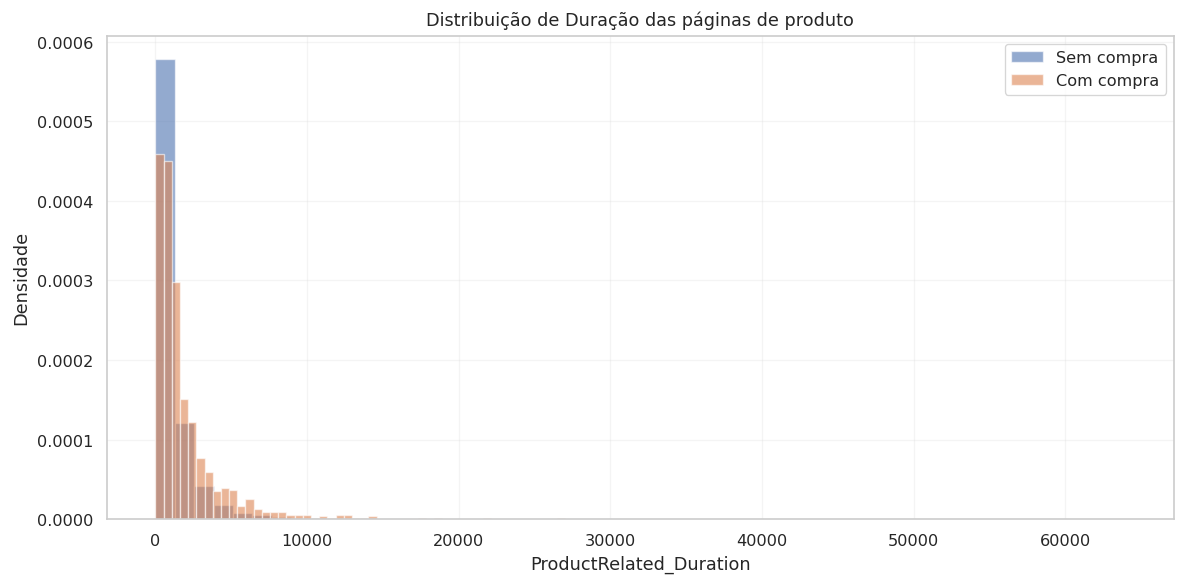

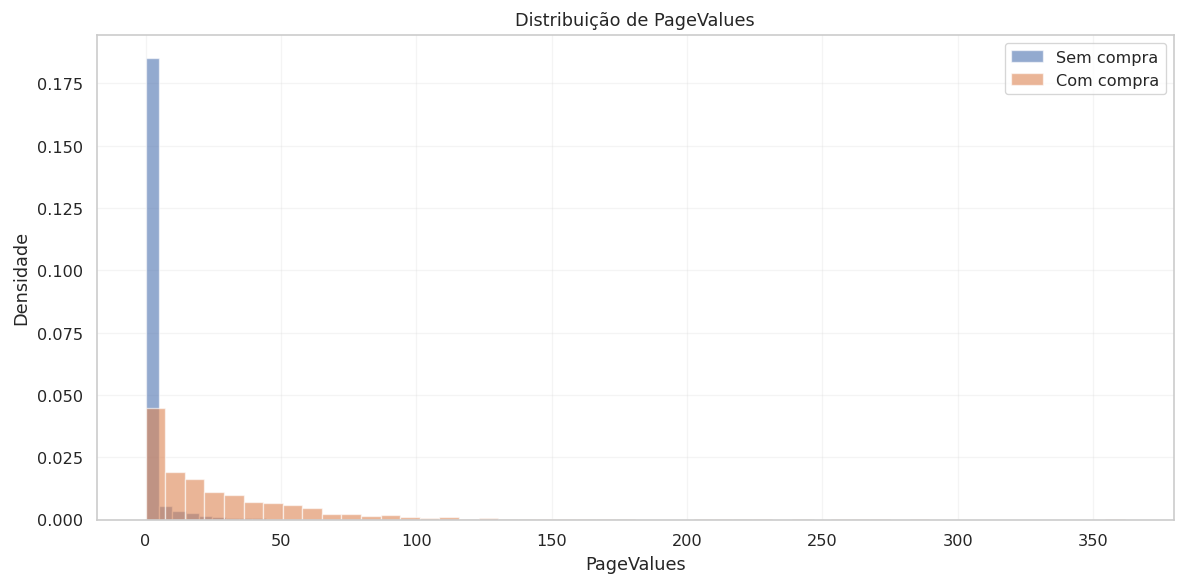

In [6]:
import matplotlib.pyplot as plt

variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

nomes = {
    'ProductRelated_Duration': 'Duração das páginas de produto',
    'PageValues': 'PageValues'
}

for variavel in variaveis_artigo:

    plt.figure(figsize=(10, 5))

    plt.hist(
        df.loc[df['Revenue'] == False, variavel],
        bins=50,
        alpha=0.6,
        label='Sem compra',
        density=True
    )

    plt.hist(
        df.loc[df['Revenue'] == True, variavel],
        bins=50,
        alpha=0.6,
        label='Com compra',
        density=True
    )

    plt.title(f'Distribuição de {nomes[variavel]}')
    plt.xlabel(variavel)
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

## 8. Comparação Visual por Boxplots

Os boxplots são utilizados para comparar a distribuição das variáveis `ProductRelated_Duration` e `PageValues` entre sessões com e sem compra. Esse tipo de gráfico permite visualizar a mediana, a amplitude interquartil e a presença de valores extremos.

Devido à assimetria e à amplitude das distribuições, os gráficos são apresentados utilizando a transformação \(log(1+x) \), exclusivamente para fins de visualização. Essa transformação permite reduzir o efeito de valores muito elevados e facilitar a comparação visual entre os grupos, preservando os valores zero.

A transformação não altera os dados utilizados nas análises estatísticas inferenciais, sendo aplicada apenas à construção dos gráficos.


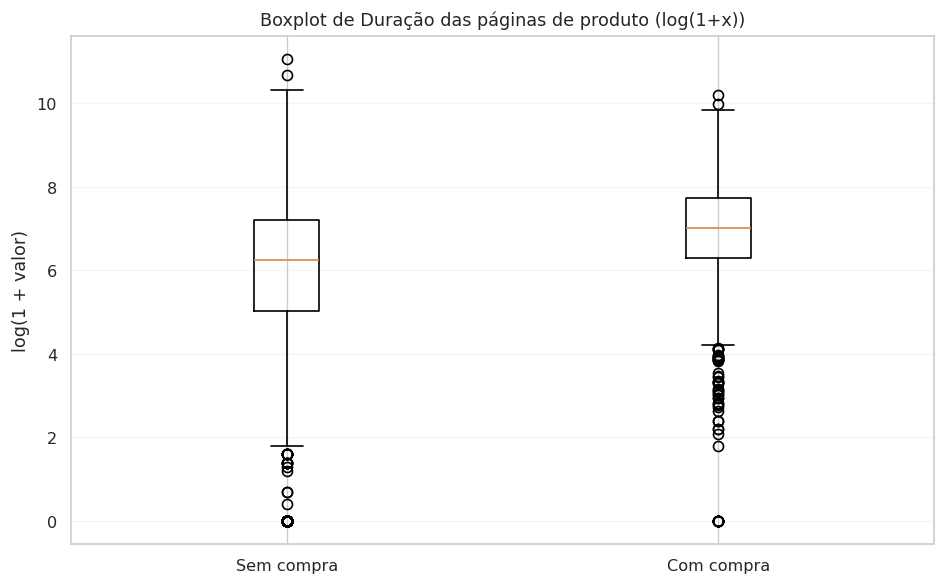

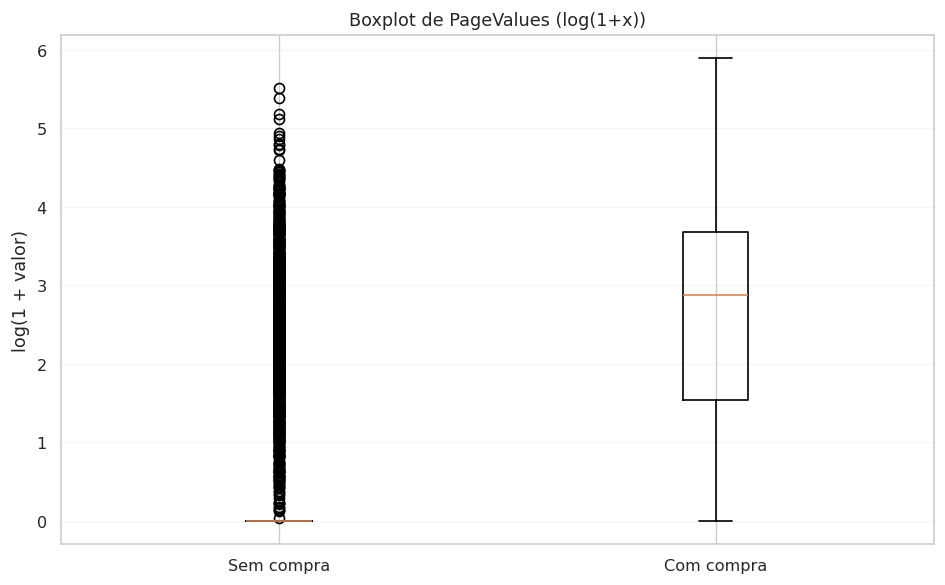

In [7]:
import numpy as np
import matplotlib.pyplot as plt

variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

nomes = {
    'ProductRelated_Duration': 'Duração das páginas de produto',
    'PageValues': 'PageValues'
}

for variavel in variaveis_artigo:

    dados_sem_compra = df.loc[df['Revenue'] == False, variavel]
    dados_com_compra = df.loc[df['Revenue'] == True, variavel]

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        [
            np.log1p(dados_sem_compra),
            np.log1p(dados_com_compra)
        ],
        tick_labels=['Sem compra', 'Com compra']
    )

    plt.title(f'Boxplot de {nomes[variavel]} (log(1+x))')
    plt.ylabel('log(1 + valor)')
    plt.grid(axis='y', alpha=0.2)
    plt.tight_layout()
    plt.show()

## 9. Investigação da Relação entre Quantidade de Páginas e Duração

A variável `ProductRelated_Duration` representa o tempo total de navegação em páginas relacionadas a produtos, enquanto `ProductRelated` representa a quantidade dessas páginas visitadas durante a sessão.

A quantidade de páginas visitadas pode influenciar diretamente o tempo total de navegação. Dessa forma, diferenças na duração entre sessões com e sem compra podem estar parcialmente relacionadas à quantidade de páginas acessadas, e não exclusivamente a diferenças no comportamento de navegação.

Para investigar essa relação, calcula-se a correlação de Spearman entre a quantidade de páginas visitadas (`ProductRelated`) e a duração total de navegação (`ProductRelated_Duration`), considerando o conjunto completo e separadamente os grupos de sessões com e sem compra.

Essa análise exploratória permite avaliar a associação entre as variáveis, mas não estabelece causalidade nem elimina possíveis fatores de confusão.


In [8]:
from scipy.stats import spearmanr

grupos_analise = {
    'Total': df,
    'Sem compra': df[df['Revenue'] == False],
    'Com compra': df[df['Revenue'] == True]
}

resultados_correlacao = []

for nome_grupo, dados in grupos_analise.items():

    rho, p_valor = spearmanr(
        dados['ProductRelated'],
        dados['ProductRelated_Duration']
    )

    resultados_correlacao.append({
        'Grupo': nome_grupo,
        'N': len(dados),
        'Correlação de Spearman': rho,
        'p-valor': p_valor
    })

tabela_correlacao = pd.DataFrame(resultados_correlacao)

display(
    tabela_correlacao.style
    .format({
        'Correlação de Spearman': '{:.4f}',
        'p-valor': '{:.6g}'
    })
    .set_caption("Associação entre quantidade de páginas e duração de navegação")
)

,Grupo,N,Correlação de Spearman,p-valor
0,Total,12330,0.8827,0
1,Sem compra,10422,0.8819,0
2,Com compra,1908,0.8574,0


## 10. Comparação entre Grupos pelo Teste de Mann–Whitney (Bilateral)

Para avaliar diferenças nas distribuições das variáveis `ProductRelated_Duration` e `PageValues` entre sessões com e sem compra, utiliza-se o teste não paramétrico de Mann–Whitney U.

Nesta etapa, adota-se a abordagem bilateral, permitindo identificar diferenças entre os grupos independentemente da direção. A hipótese nula estabelece que as distribuições dos grupos são equivalentes, enquanto a hipótese alternativa indica que existem diferenças entre elas.

Os testes são realizados individualmente para cada variável, considerando sessões com compra e sessões sem compra. Para controlar o erro associado à realização de múltiplos testes, aplica-se a correção de Holm aos p-valores obtidos.

Adota-se nível de significância de 5% (α = 0,05). Os resultados são apresentados por meio da estatística U, dos p-valores originais e ajustados, permitindo verificar a significância estatística das comparações.


In [9]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

resultados_mw = []

for variavel in variaveis_artigo:

    sem_compra = df.loc[df['Revenue'] == False, variavel]
    com_compra = df.loc[df['Revenue'] == True, variavel]

    resultado = mannwhitneyu(
        com_compra,
        sem_compra,
        alternative='two-sided'
    )

    resultados_mw.append({
        'Variável': variavel,
        'U': resultado.statistic,
        'p-valor': resultado.pvalue
    })

tabela_mw = pd.DataFrame(resultados_mw)

# Correção de Holm
tabela_mw['p-valor ajustado (Holm)'] = multipletests(
    tabela_mw['p-valor'],
    method='holm'
)[1]

tabela_mw['Significativo (α = 0,05)'] = (
    tabela_mw['p-valor ajustado (Holm)'] < 0.05
)

display(
    tabela_mw.style
    .format({
        'U': '{:,.0f}',
        'p-valor': '{:.6g}',
        'p-valor ajustado (Holm)': '{:.6g}'
    })
    .set_caption("Teste de Mann–Whitney bilateral com correção de Holm")
)

,Variável,U,p-valor,p-valor ajustado (Holm),"Significativo (α = 0,05)"
0,ProductRelated_Duration,"13,382,713",5.33227e-128,5.33227e-128,True
1,PageValues,"17,166,757",0,0,True


## 11. Tamanho de Efeito: Delta de Cliff e Intervalo de Confiança

Para complementar os testes de Mann–Whitney, calcula-se o Delta de Cliff, uma medida não paramétrica de tamanho de efeito que quantifica a diferença entre duas distribuições.

O Delta de Cliff varia entre −1 e +1. Valores positivos indicam predominância de valores maiores no grupo de sessões com compra, enquanto valores negativos indicam predominância de valores menores. Valores próximos de zero sugerem menor diferenciação entre os grupos.

Para avaliar a incerteza da estimativa, utiliza-se o método bootstrap com 2.000 reamostragens independentes de cada grupo, com reposição, e nível de confiança de 95%. A utilização do intervalo de confiança permite complementar a interpretação da magnitude do efeito observado.

As estimativas são calculadas para `ProductRelated_Duration` e `PageValues`, considerando sessões com compra em comparação às sessões sem compra.


In [10]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

def calcular_delta_cliff(grupo1, grupo2):
    n1 = len(grupo1)
    n2 = len(grupo2)

    U = mannwhitneyu(
        grupo1,
        grupo2,
        alternative='two-sided'
    ).statistic

    delta = (2 * U / (n1 * n2)) - 1

    return delta


rng = np.random.default_rng(42)

variaveis_artigo = ['ProductRelated_Duration', 'PageValues']

resultados_delta = []

for variavel in variaveis_artigo:

    com_compra = df.loc[df['Revenue'] == True, variavel].to_numpy()
    sem_compra = df.loc[df['Revenue'] == False, variavel].to_numpy()

    delta_observado = calcular_delta_cliff(com_compra, sem_compra)

    deltas_bootstrap = []

    for _ in range(2000):

        amostra_com = rng.choice(
            com_compra,
            size=len(com_compra),
            replace=True
        )

        amostra_sem = rng.choice(
            sem_compra,
            size=len(sem_compra),
            replace=True
        )

        delta_boot = calcular_delta_cliff(amostra_com, amostra_sem)

        deltas_bootstrap.append(delta_boot)

    ic_inferior = np.percentile(deltas_bootstrap, 2.5)
    ic_superior = np.percentile(deltas_bootstrap, 97.5)

    resultados_delta.append({
        'Variável': variavel,
        'Delta de Cliff': delta_observado,
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior
    })

tabela_delta = pd.DataFrame(resultados_delta)

display(
    tabela_delta.style
    .format({
        'Delta de Cliff': '{:.4f}',
        'IC 95% inferior': '{:.4f}',
        'IC 95% superior': '{:.4f}'
    })
    .set_caption("Delta de Cliff e intervalo de confiança bootstrap de 95%")
)

,Variável,Delta de Cliff,IC 95% inferior,IC 95% superior
0,ProductRelated_Duration,0.3460,0.3215,0.3698
1,PageValues,0.7266,0.7066,0.7470


## 12. Análise de Sensibilidade para `ProductRelated_Duration`

Considerando a presença de valores iguais a zero em `ProductRelated_Duration`, realiza-se uma análise de sensibilidade complementar, excluindo essas observações e repetindo a comparação entre sessões com e sem compra.

O objetivo é verificar se a diferença observada entre os grupos permanece quando são consideradas apenas sessões com duração positiva de navegação em páginas relacionadas a produtos.

Essa análise não substitui a comparação principal, pois a exclusão de observações com duração zero altera o conjunto de sessões analisadas e pode introduzir seleção. Seus resultados são interpretados como evidência complementar de robustez, e não como uma estimativa representativa de todas as sessões.


In [11]:
from scipy.stats import mannwhitneyu

variavel = 'ProductRelated_Duration'

com_compra_original = df.loc[
    df['Revenue'] == True, variavel
]

sem_compra_original = df.loc[
    df['Revenue'] == False, variavel
]

# Análise principal
resultado_original = mannwhitneyu(
    com_compra_original,
    sem_compra_original,
    alternative='two-sided'
)

# Análise de sensibilidade
com_compra_positivos = com_compra_original[
    com_compra_original > 0
]

sem_compra_positivos = sem_compra_original[
    sem_compra_original > 0
]

resultado_positivos = mannwhitneyu(
    com_compra_positivos,
    sem_compra_positivos,
    alternative='two-sided'
)

tabela_sensibilidade = pd.DataFrame([
    {
        'Análise': 'Original (todos os valores)',
        'N com compra': len(com_compra_original),
        'N sem compra': len(sem_compra_original),
        'U': resultado_original.statistic,
        'p-valor': resultado_original.pvalue
    },
    {
        'Análise': 'Somente duração positiva',
        'N com compra': len(com_compra_positivos),
        'N sem compra': len(sem_compra_positivos),
        'U': resultado_positivos.statistic,
        'p-valor': resultado_positivos.pvalue
    }
])

display(
    tabela_sensibilidade.style
    .format({
        'U': '{:,.0f}',
        'p-valor': '{:.6g}'
    })
    .set_caption("Comparação de sensibilidade para ProductRelated_Duration")
)

,Análise,N com compra,N sem compra,U,p-valor
0,Original (todos os valores),1908,10422,"13,382,713",5.33227e-128
1,Somente duração positiva,1895,9680,"11,971,800",2.34614e-98


## 13. Análise Complementar de `PageValues` e Conversão

A variável `PageValues` representa o valor associado às páginas visitadas antes de uma transação, conforme a definição do conjunto de dados. Sua relação com a conversão exige cautela interpretativa, uma vez que essa métrica está conceitualmente vinculada ao processo de transação e pode refletir informações relacionadas ao próprio resultado da sessão.

Como análise complementar, as sessões são classificadas em dois grupos de acordo com `PageValues`: valores iguais a zero e valores maiores que zero. Em seguida, avalia-se a associação entre essa classificação e a variável `Revenue` por meio do teste qui-quadrado de independência.

Essa análise tem caráter exploratório e descritivo da associação. Os resultados não devem ser interpretados como evidência de causalidade, capacidade preditiva independente ou confirmação de que `PageValues` constitui um antecedente da compra.


In [12]:
df['PageValues_Positive'] = df['PageValues'] > 0

tabela_contingencia = pd.crosstab(
    df['PageValues_Positive'],
    df['Revenue']
)

print("Tabela de contingência:")
display(tabela_contingencia)

chi2, p_valor, graus_liberdade, frequencias_esperadas = (
    chi2_contingency(tabela_contingencia)
)

resultado_chi2 = pd.DataFrame([{
    'Qui-quadrado': chi2,
    'Graus de liberdade': graus_liberdade,
    'p-valor': p_valor
}])

display(
    resultado_chi2.style
    .format({
        'Qui-quadrado': '{:.4f}',
        'p-valor': '{:.6g}'
    })
    .set_caption("Teste qui-quadrado de independência entre PageValues positivo e Revenue")
)

Tabela de contingência:


Revenue,False,True
PageValues_Positive,,
False,9230,370
True,1192,1538


,Qui-quadrado,Graus de liberdade,p-valor
0,4472.1113,1,0


## 14. Consolidação dos Resultados Inferenciais

Nesta etapa, consolidam-se os resultados dos testes de Mann–Whitney bilateral, com correção de Holm, e as estimativas de tamanho de efeito pelo Delta de Cliff, acompanhadas de seus intervalos de confiança de 95%.

A consolidação permite comparar, para cada variável, a significância estatística e a magnitude da diferença observada entre sessões com e sem compra. Essa apresentação facilita a interpretação conjunta dos resultados e a verificação da consistência dos valores antes de sua incorporação ao artigo.

Os resultados reunidos referem-se às análises principais. As análises de sensibilidade e complementares são interpretadas separadamente.


In [13]:
tabela_consolidada = tabela_mw.merge(
    tabela_delta,
    on='Variável',
    how='inner'
)

display(
    tabela_consolidada.style
    .format({
        'U': '{:,.0f}',
        'p-valor': '{:.6g}',
        'p-valor ajustado (Holm)': '{:.6g}',
        'Delta de Cliff': '{:.4f}',
        'IC 95% inferior': '{:.4f}',
        'IC 95% superior': '{:.4f}'
    })
    .set_caption("Consolidação dos testes de Mann–Whitney e tamanhos de efeito")
)

,Variável,U,p-valor,p-valor ajustado (Holm),"Significativo (α = 0,05)",Delta de Cliff,IC 95% inferior,IC 95% superior
0,ProductRelated_Duration,"13,382,713",5.33227e-128,5.33227e-128,True,0.3460,0.3215,0.3698
1,PageValues,"17,166,757",0,0,True,0.7266,0.7066,0.7470


### 14.1. Valores Numéricos para Transcrição no Artigo


In [14]:

# Exibição dos valores numéricos para transcrição ao artigo

colunas_resultado = [
    'Variável',
    'U',
    'p-valor',
    'p-valor ajustado (Holm)',
    'Delta de Cliff',
    'IC 95% inferior',
    'IC 95% superior'
]

print(tabela_consolidada[colunas_resultado].to_string(index=False))


               Variável             U  p-valor  p-valor ajustado (Holm)  Delta de Cliff  IC 95% inferior  IC 95% superior
ProductRelated_Duration 13382713.0000   0.0000                   0.0000          0.3460           0.3215           0.3698
             PageValues 17166757.0000   0.0000                   0.0000          0.7266           0.7066           0.7470


## 15. Análise Ajustada: Duração, Conversão e Quantidade de Páginas

Conforme identificado na análise exploratória da Seção 9, o tempo total de navegação (`ProductRelated_Duration`) apresenta forte associação com a quantidade de páginas de produtos visitadas (`ProductRelated`). Para avaliar se a diferença na duração entre sessões com e sem compra persiste independentemente do volume de páginas acessadas, estima-se um modelo de regressão linear múltipla por Mínimos Quadrados Ordinários (OLS).

Devido à acentuada assimetria positiva e à presença de valores iguais a zero na duração, aplica-se a transformação \( log(1+x) ) à variável dependente. O modelo incorpora a variável indicadora de conversão (`Revenue_Bin`) e controla o efeito linear pela quantidade de páginas visitadas (`ProductRelated`). Para assegurar a validade da inferência estatística diante de eventual heterocedasticidade nos resíduos, empregam-se erros-padrão robustos de White (estimador HC3).

In [15]:
import statsmodels.formula.api as smf
import numpy as np

df_modelo = df.copy()

df_modelo['Log_ProductRelated_Duration'] = np.log1p(
    df_modelo['ProductRelated_Duration']
)

df_modelo['Revenue_Bin'] = df_modelo['Revenue'].astype(int)

# Modelo ajustado
modelo_ajustado = smf.ols(
    'Log_ProductRelated_Duration ~ Revenue_Bin + ProductRelated',
    data=df_modelo
).fit(cov_type='HC3')

print(modelo_ajustado.summary())


                                 OLS Regression Results                                
Dep. Variable:     Log_ProductRelated_Duration   R-squared:                       0.317
Model:                                     OLS   Adj. R-squared:                  0.317
Method:                          Least Squares   F-statistic:                     867.7
Date:                         Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                                 02:23:37   Log-Likelihood:                -23951.
No. Observations:                        12330   AIC:                         4.791e+04
Df Residuals:                            12327   BIC:                         4.793e+04
Df Model:                                    2                                         
Covariance Type:                           HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------

## 16. Geração das Figuras Finais e Estatísticas Complementares para Publicação

Nesta seção final, são geradas e exportadas em alta resolução (300 DPI) as figuras selecionadas para compor o manuscrito científico, bem como as métricas descritivas complementares de forma da distribuição:



- **Figura 1 :** Boxplot comparativo de `ProductRelated_Duration` em escala \( log(1+x) ), com supressão visual de valores extremos (*outliers*) para evidenciar o deslocamento das medianas e intervalos interquartis entre sessões convertidas e não convertidas.

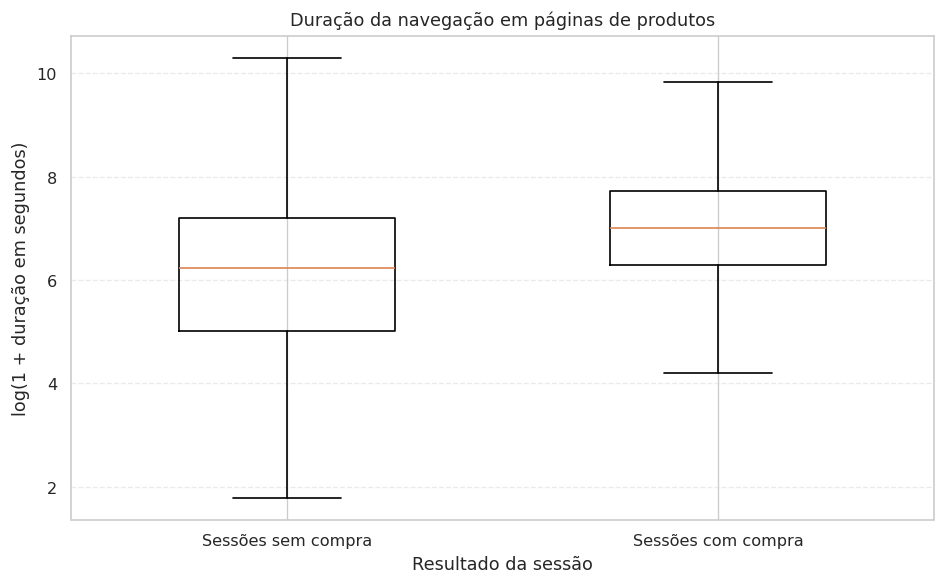

In [16]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

dados_plot = [
    np.log1p(df.loc[df['Revenue'] == False, 'ProductRelated_Duration']),
    np.log1p(df.loc[df['Revenue'] == True, 'ProductRelated_Duration'])
]

plt.boxplot(
    dados_plot,
    labels=['Sessões sem compra', 'Sessões com compra'],
    showfliers=False,
    widths=0.5
)

plt.ylabel('log(1 + duração em segundos)')
plt.xlabel('Resultado da sessão')
plt.title('Duração da navegação em páginas de produtos')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    'figura1_productrelated_duration.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

- **Figura 2 (`figura2_pagevalues_positive.png`):** Gráfico de barras ilustrando a proporção percentual de sessões que registraram `PageValues > 0` em cada grupo de desfecho.

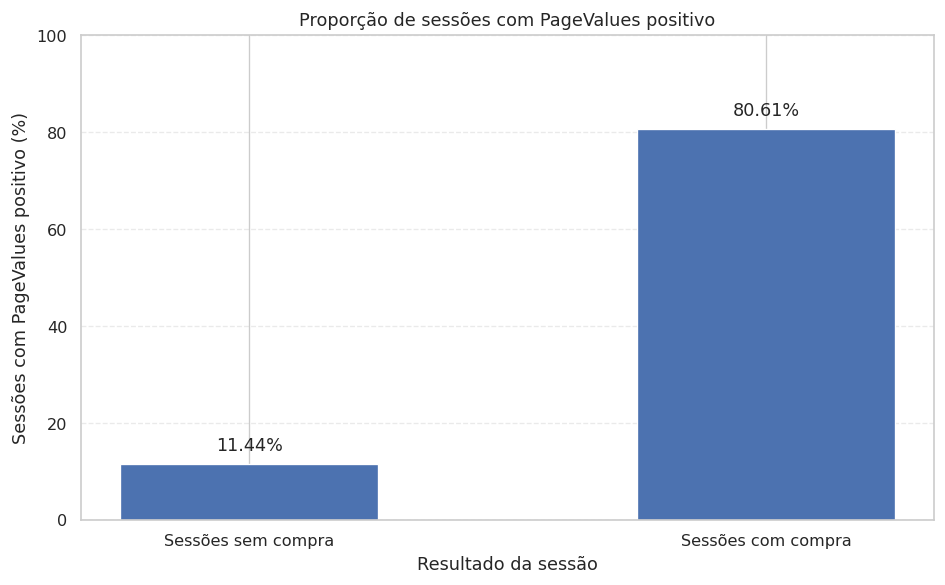

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

proporcoes = (
    df.groupby('Revenue')['PageValues_Positive']
    .mean() * 100
)

labels = ['Sessões sem compra', 'Sessões com compra']
valores = [proporcoes.loc[False], proporcoes.loc[True]]

plt.figure(figsize=(8, 5))

barras = plt.bar(labels, valores, width=0.5)

plt.ylabel('Sessões com PageValues positivo (%)')
plt.xlabel('Resultado da sessão')
plt.title('Proporção de sessões com PageValues positivo')

plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', alpha=0.4)

for barra, valor in zip(barras, valores):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 2,
        f'{valor:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    'figura2_pagevalues_positive.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

- **Figura 3 (`figura3_histograma_productrelated.png`):** Histograma de densidade sobreposto da duração transformada em \( log(1+x) \), permitindo visualizar a sobreposição das distribuições e a concentração modal.

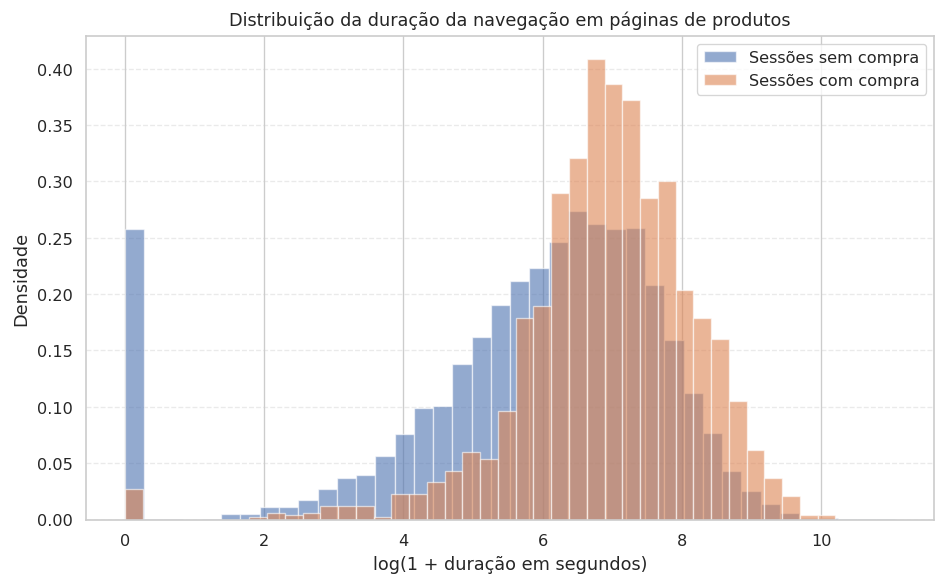

In [18]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

sem_compra = np.log1p(
    df.loc[df['Revenue'] == False, 'ProductRelated_Duration']
)

com_compra = np.log1p(
    df.loc[df['Revenue'] == True, 'ProductRelated_Duration']
)

plt.hist(
    sem_compra,
    bins=40,
    density=True,
    alpha=0.6,
    label='Sessões sem compra'
)

plt.hist(
    com_compra,
    bins=40,
    density=True,
    alpha=0.6,
    label='Sessões com compra'
)

plt.xlabel('log(1 + duração em segundos)')
plt.ylabel('Densidade')
plt.title('Distribuição da duração da navegação em páginas de produtos')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    'figura3_histograma_productrelated.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

- **Estatísticas de Forma:** Cálculo adicional dos coeficientes de assimetria (*skewness*) e curtose (*kurtosis*) na escala original para caracterização formal da não normalidade das amostras.

In [19]:
for grupo, dados in [
    ('Sem compra', df.loc[df['Revenue'] == False, 'ProductRelated_Duration']),
    ('Com compra', df.loc[df['Revenue'] == True, 'ProductRelated_Duration'])
]:
    print(f'\n{grupo}')
    print(f'Média: {dados.mean():.2f}')
    print(f'Mediana: {dados.median():.2f}')
    print(f'Desvio padrão: {dados.std():.2f}')
    print(f'Assimetria: {dados.skew():.4f}')
    print(f'Curtose: {dados.kurtosis():.4f}')
    print(f'Zeros: {(dados == 0).sum()} ({(dados == 0).mean()*100:.2f}%)')


Sem compra
Média: 1069.99
Mediana: 510.19
Desvio padrão: 1803.80
Assimetria: 8.8330
Curtose: 197.1030
Zeros: 742 (7.12%)

Com compra
Média: 1876.21
Mediana: 1109.91
Desvio padrão: 2312.21
Assimetria: 3.3376
Curtose: 17.7251
Zeros: 13 (0.68%)
